# Понижение размерности на медицинском датасете

In [21]:
%pip install umap-learn -q

Note: you may need to restart the kernel to use updated packages.


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

import warnings
warnings.filterwarnings('ignore')

# Настройки графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [23]:
# Загружаем датасет
data = load_breast_cancer()
X = data.data
y = data.target

print(f"Исходная размерность: {X.shape}")
print(f"Классы: {data.target_names} (0 - злокачественная, 1 - доброкачественная)")

# Масштабируем признаки
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Создадим DataFrame для удобства визуализации
df_pca = pd.DataFrame(X_scaled, columns=data.feature_names)
df_pca['target'] = y

Исходная размерность: (569, 30)
Классы: ['malignant' 'benign'] (0 - злокачественная, 1 - доброкачественная)


# PCA (Метод главных компонент)
Сначала посмотрим, сколько компонент нам нужно, чтобы сохранить 90% и 95% дисперсии (слайд 19). Построим график накопленной дисперсии.

Компонент для 90% дисперсии: 7
Компонент для 95% дисперсии: 10


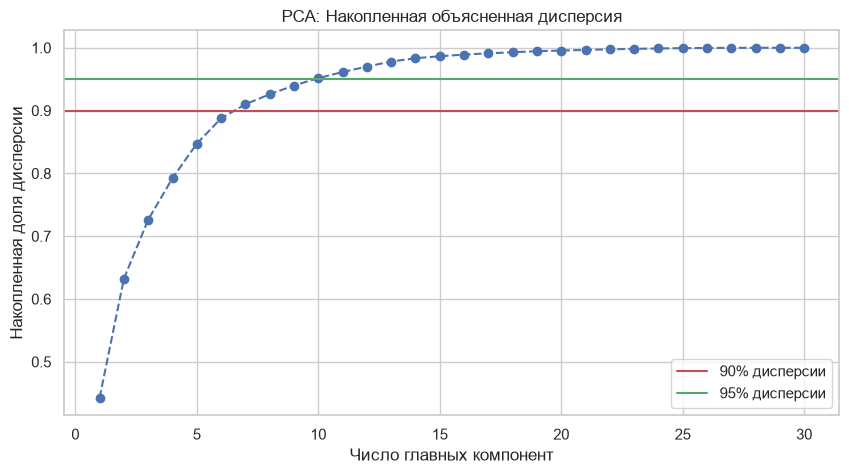

In [24]:
# Обучаем PCA на всех компонентах, чтобы посмотреть дисперсию
pca_full = PCA().fit(X_scaled)

# Считаем накопленную долю дисперсии
cum_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Находим, сколько компонент нужно для 90% и 95%
n_90 = np.argmax(cum_variance >= 0.90) + 1
n_95 = np.argmax(cum_variance >= 0.95) + 1

print(f"Компонент для 90% дисперсии: {n_90}")
print(f"Компонент для 95% дисперсии: {n_95}")

# Строим график
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cum_variance) + 1), cum_variance, marker='o', linestyle='--', color='b')
plt.axhline(y=0.90, color='r', linestyle='-', label='90% дисперсии')
plt.axhline(y=0.95, color='g', linestyle='-', label='95% дисперсии')
plt.xlabel('Число главных компонент')
plt.ylabel('Накопленная доля дисперсии')
plt.title('PCA: Накопленная объясненная дисперсия')
plt.legend()
plt.grid(True)
plt.show()

# Визуализация PCA (2 компоненты)
Оставим только 2 компоненты для визуализации и посмотрим, как данные выглядят в 2D-пространстве.

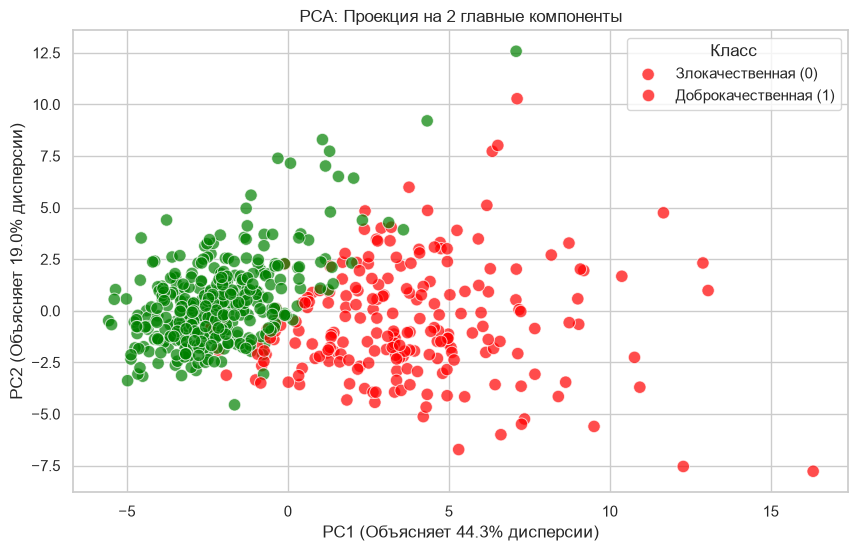

In [25]:
# Оставляем 2 компоненты для визуализации
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

# Визуализация
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=df_pca['target'], 
                palette={0: 'red', 1: 'green'}, alpha=0.7, s=80)
plt.xlabel(f'PC1 (Объясняет {pca_2d.explained_variance_ratio_[0]:.1%} дисперсии)')
plt.ylabel(f'PC2 (Объясняет {pca_2d.explained_variance_ratio_[1]:.1%} дисперсии)')
plt.title('PCA: Проекция на 2 главные компоненты')
plt.legend(title='Класс', labels=['Злокачественная (0)', 'Доброкачественная (1)'])
plt.show()

PCA — линейный метод. Он сохраняет глобальную структуру, но классы могут немного пересекаться, так как он ищет направления максимальной дисперсии, а не максимального разделения классов.

#  t-SNE (Нелинейный метод)
t-SNE сохраняет локальные соседства. Он отлично подходит для визуализации, но на нем нельзя интерпретировать глобальные расстояния (слайд 18).
Важно: параметр perplexity можно менять (обычно от 5 до 50). Он отвечает за баланс между локальной и глобальной структурой.

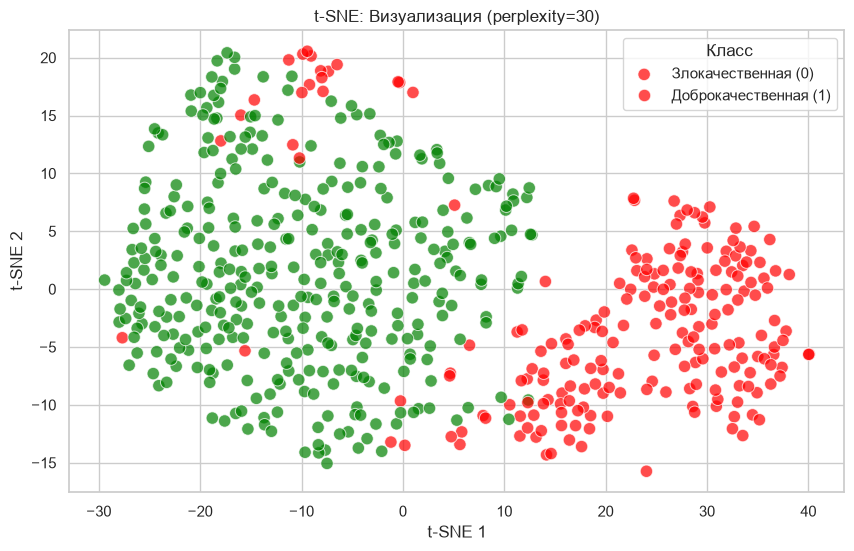

In [26]:
# t-SNE может работать долго, поэтому используем n_jobs=-1 (все ядра)
tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_jobs=-1)
X_tsne = tsne.fit_transform(X_scaled)

# Визуализация
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=df_pca['target'], 
                palette={0: 'red', 1: 'green'}, alpha=0.7, s=80)
plt.title('t-SNE: Визуализация (perplexity=30)')
plt.legend(title='Класс', labels=['Злокачественная (0)', 'Доброкачественная (1)'])
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.show()

# UMAP (Альтернатива)
UMAP (Uniform Manifold Approximation and Projection) — это более современный алгоритм. Он работает быстрее t-SNE, лучше сохраняет глобальную структуру и может проецировать новые данные (в отличие от t-SNE).
Параметр n_neighbors контролирует баланс локального и глобального (аналог perplexity).

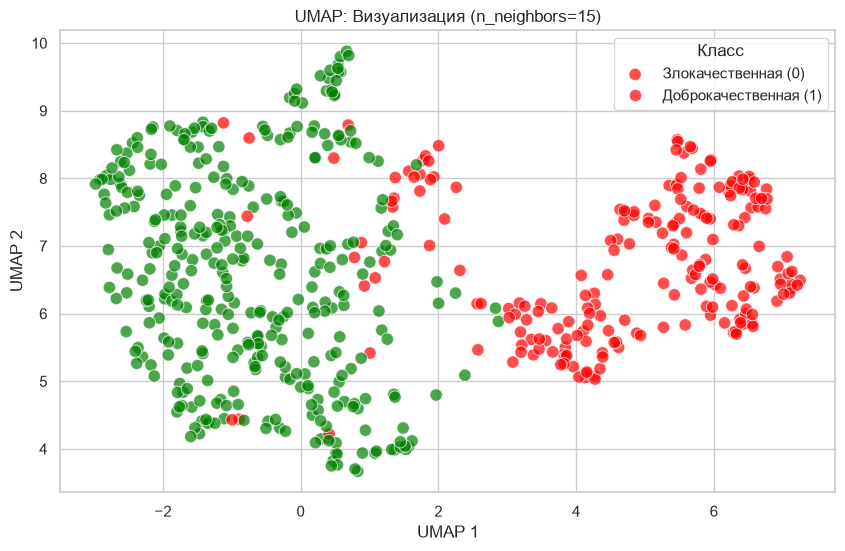

In [27]:
# UMAP
umap_reducer = umap.UMAP(n_components=2, n_neighbors=10, min_dist=0.1, random_state=42)
X_umap = umap_reducer.fit_transform(X_scaled)

# Визуализация
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_umap[:, 0], y=X_umap[:, 1], hue=df_pca['target'], 
                palette={0: 'red', 1: 'green'}, alpha=0.7, s=80)
plt.title('UMAP: Визуализация (n_neighbors=15)')
plt.legend(title='Класс', labels=['Злокачественная (0)', 'Доброкачественная (1)'])
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.show()

# Связь с кластеризацией
Если мы применим K-Means к нашему 2D-пространству PCA (где осталось 2 компоненты), найдет ли он те же группы, что и истинные метки?
В реальной жизни меток у нас может не быть, и мы используем понижение размерности, чтобы потом кластеризовать данные.



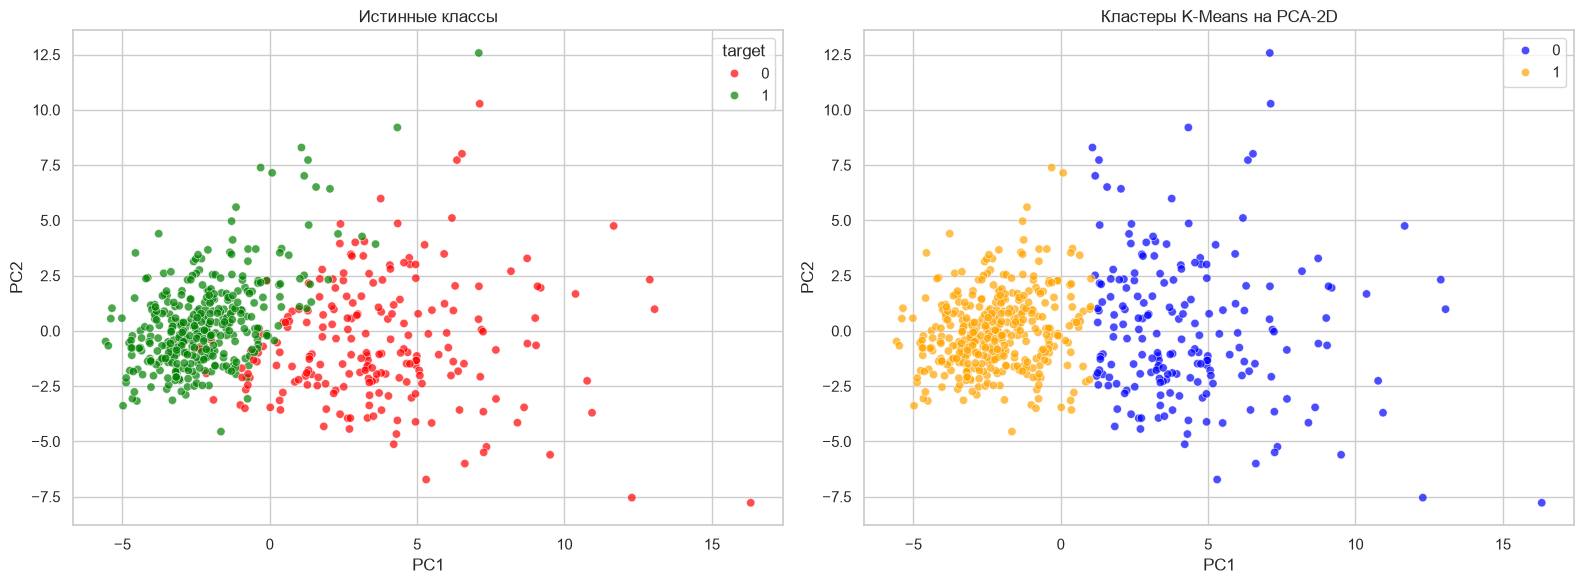

In [28]:
from sklearn.cluster import KMeans

# Обучаем K-Means на 2D-данных PCA
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_pca_2d)

# Визуализация: слева - истинные метки, справа - предсказанные кластеры
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Истинные метки
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=df_pca['target'], 
                palette={0: 'red', 1: 'green'}, alpha=0.7, ax=axes[0])
axes[0].set_title('Истинные классы')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

# Кластеры K-Means
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=cluster_labels, 
                palette={0: 'blue', 1: 'orange'}, alpha=0.7, ax=axes[1])
axes[1].set_title('Кластеры K-Means на PCA-2D')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()

Вывод: Хотя K-Means на 2D-данных PCA может найти два кластера, они не идеально совпадают с истинными метками, потому что PCA сохраняет дисперсию, а не разделение классов. Это наглядно показывает ограничения обучения без учителя.

# Если выбрать метод неудачно (DBSCAN)

DBSCAN нашел кластеров: 7
Шумовых точек: 179 (из 569)


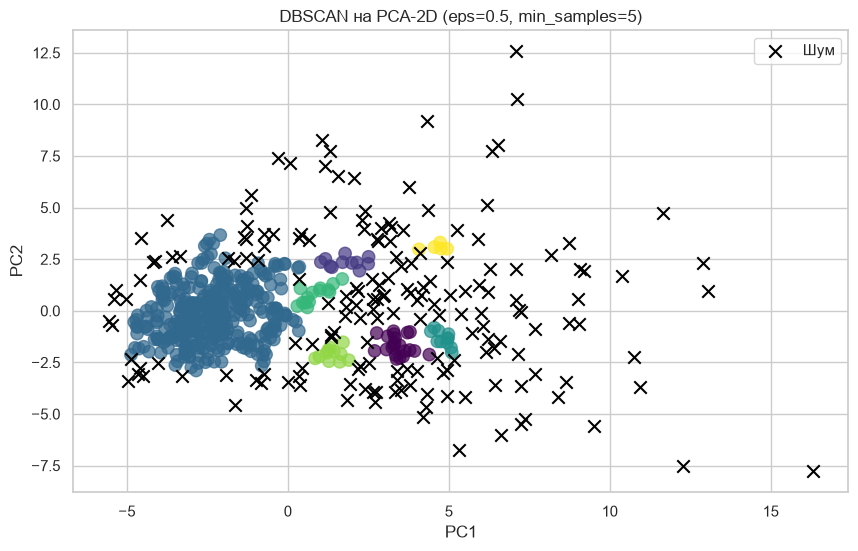

In [29]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score

# 1. Пробуем DBSCAN на 2D-данных PCA
# Подбираем eps и min_samples (по умолчанию можно взять eps=0.5, min_samples=5)
dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_pca_2d)

# 2. Смотрим, что получилось
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print(f"DBSCAN нашел кластеров: {n_clusters}")
print(f"Шумовых точек: {n_noise} (из {len(X_pca_2d)})")

# 3. Визуализация
plt.figure(figsize=(10, 6))
# Выделяем шум (label = -1) черным цветом
mask_noise = dbscan_labels == -1
plt.scatter(X_pca_2d[~mask_noise, 0], X_pca_2d[~mask_noise, 1], 
            c=dbscan_labels[~mask_noise], cmap='viridis', alpha=0.7, s=80)
plt.scatter(X_pca_2d[mask_noise, 0], X_pca_2d[mask_noise, 1], 
            c='black', marker='x', label='Шум', s=80)

plt.title('DBSCAN на PCA-2D (eps=0.5, min_samples=5)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()

Посмотрите на график: Вы увидите, что DBSCAN не смог найти два больших кластера. Он разбил на мелкие и пометил часть точек как шум.

Почему? Потому что данные в Breast Cancer — это плотное «облако», а не отдельные изолированные островки. DBSCAN ищет области, где точки расположены близко друг к другу (плотность), но в этом датасете плотность везде примерно одинаковая.

Вывод: Алгоритмы кластеризации не универсальны. Подбор алгоритма зависит от формы кластеров.